# Notebook 08 — Uncertainty and Ranking Stability

I ask which areas can honestly be described as among the lowest or highest for healthy life expectancy, and which estimates cannot be told apart by rank. The published values stay visible; I add the uncertainty around their order.

A rank describes an area-level estimate. It does not describe the people who live there.

## Setting up

I use the same project discovery and data helpers as the earlier notebooks. The output folder is new for this phase. I check the saved uncertainty values from the earlier neighbour analysis as well as the interval calculation.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
%matplotlib inline

project_folder = next(p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "Data/Cleaned/Wide/msoa_wide_660.csv").is_file()
    or (p / "data/cleaned/Wide/msoa_wide_660.csv").is_file())
data_folder = project_folder / ("Data" if (project_folder / "Data").is_dir() else "data")

def project_data(relative_path):
    parts = Path(relative_path).parts
    if data_folder.name == "data":
        parts = (parts[0].lower(), *parts[1:])
    return data_folder.joinpath(*parts)

expected_environment = project_folder.parent / ".venv-unit3"
if expected_environment.is_dir():
    assert Path(sys.prefix).resolve() == expected_environment.resolve(), "Select the Unit 3 environment."

def raw_file(filename):
    candidates = sorted(project_data("Raw").rglob(filename))
    if not candidates:
        raise FileNotFoundError(f"Raw source not found in the project's raw folder: {filename}")
    return candidates[0]

def read_csv(relative):
    return pd.read_csv(project_data(relative))

output_folder = project_data("Cleaned/Uncertainty")
figure_folder = project_data("Cleaned/Uncertainty/figures")
assert not output_folder.exists(), "The phase output folder already exists; check before overwriting."
assert not figure_folder.exists()
output_folder.mkdir()
figure_folder.mkdir()

def save_csv(table, filename, index=False):
    path = output_folder / filename
    assert not path.exists() and not path.is_symlink()
    with path.open("w", encoding="utf-8", newline="") as stream:
        table.to_csv(stream, index=index)
    check = pd.read_csv(path)
    expected = table.reset_index() if index else table.reset_index(drop=True)
    pd.testing.assert_frame_equal(check, expected, check_dtype=False)

def save_json(value, filename):
    path = output_folder / filename
    assert not path.exists() and not path.is_symlink()
    with path.open("w", encoding="utf-8") as stream:
        json.dump(value, stream, indent=2, ensure_ascii=False, allow_nan=False)
    assert json.loads(path.read_text(encoding="utf-8")) == value

def save_figure(figure, filename):
    path = figure_folder / filename
    assert not path.exists() and not path.is_symlink()
    figure.savefig(path, bbox_inches="tight")
    assert path.is_file() and path.stat().st_size > 0
    plt.show()
    plt.close(figure)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
EXPECTED_AREAS, N_SIMULATIONS, BATCH_SIZE = 660, 10_000, 200
RANK_SEED, Z_CUTOFF = 20261017, 1.96
BOTTOM_CUT, TOP_FIRST = 66, 595
MIDDLE_FIRST, MIDDLE_LAST = 221, 440
PALETTE = ["#243b53", "#c25024", "#087f8c", "#b54724"]

print(f"Notebook 08 settings: areas={EXPECTED_AREAS}, simulations={N_SIMULATIONS}, batch size={BATCH_SIZE}, seed={RANK_SEED}")
print(f"Bottom-tenth cut: rank {BOTTOM_CUT}; top tenth begins at rank {TOP_FIRST}.")
print(f"Standard error from a 95% interval divides its full width by 2 × {Z_CUTOFF}.")
print("Assumption: area-level HLE errors are independent, as in the earlier neighbour-gap simulation.")

Notebook 08 settings: areas=660, simulations=10000, batch size=200, seed=20261017
Bottom-tenth cut: rank 66; top tenth begins at rank 595.
Standard error from a 95% interval divides its full width by 2 × 1.96.
Assumption: area-level HLE errors are independent, as in the earlier neighbour-gap simulation.


## Checking the estimates and their standard errors

The earlier analysis derives each standard error from the full width of the average-HLE interval. I use that same calculation and compare it with the saved neighbour-pair values for every area.

In [2]:
wide = read_csv("Cleaned/Wide/msoa_wide_660.csv").sort_values("area_code").reset_index(drop=True)
assert len(wide) == EXPECTED_AREAS and wide["area_code"].is_unique
assert wide["local_area_name"].is_unique
outcome = ["hle_average", "hle_average_lci", "hle_average_uci"]
flags = ["hle_male_imputed", "student_dominated", "visitor_hub"]
assert wide[["area_code", "local_area_name", *outcome, *flags]].notna().all().all()
assert np.isfinite(wide[outcome].to_numpy()).all()
assert wide["hle_average_lci"].lt(wide["hle_average"]).all()
assert wide["hle_average"].lt(wide["hle_average_uci"]).all()
for column in flags:
    assert pd.api.types.is_bool_dtype(wide[column]) and wide[column].notna().all()

area_table = wide.set_index("area_code").copy()
area_table["se_average"] = (area_table["hle_average_uci"] - area_table["hle_average_lci"]) / (2 * Z_CUTOFF)
assert area_table["se_average"].gt(0).all()

pairs = read_csv("Cleaned/Neighbours/neighbour_pairs.csv")
saved_se = pd.concat([
    pairs[["area_a", "se_average_a"]].rename(columns={"area_a": "area_code", "se_average_a": "se_average"}),
    pairs[["area_b", "se_average_b"]].rename(columns={"area_b": "area_code", "se_average_b": "se_average"}),
], ignore_index=True)
assert saved_se["area_code"].nunique() == EXPECTED_AREAS
assert saved_se.groupby("area_code")["se_average"].nunique().eq(1).all()
saved_se = saved_se.groupby("area_code")["se_average"].first()
assert set(saved_se.index) == set(area_table.index)
np.testing.assert_allclose(area_table.loc[saved_se.index, "se_average"],
                           saved_se.reindex(area_table.index), rtol=0, atol=1e-12)

area_table["published_rank"] = area_table["hle_average"].rank(method="first").astype(int)
assert area_table["published_rank"].nunique() == EXPECTED_AREAS
print(f"I retain {len(area_table):,} areas; interval-derived standard errors match Notebook 04's saved pair values for all areas.")

I retain 660 areas; interval-derived standard errors match Notebook 04's saved pair values for all areas.


## Simulating rank uncertainty

I draw one HLE value for every area in each run, using that area's published mean and standard error. I rank the draws from lowest to highest and calculate each area's median and central rank interval.

In [3]:
rng = np.random.default_rng(RANK_SEED)
means = area_table["hle_average"].to_numpy(float)
ses = area_table["se_average"].to_numpy(float)
simulated_ranks = np.empty((N_SIMULATIONS, EXPECTED_AREAS), dtype=np.int16)
for start in range(0, N_SIMULATIONS, BATCH_SIZE):
    stop = min(start + BATCH_SIZE, N_SIMULATIONS)
    draws = rng.normal(means, ses, size=(stop - start, EXPECTED_AREAS))
    assert np.isfinite(draws).all()
    order = np.argsort(draws, axis=1, kind="stable")
    simulated_ranks[start:stop] = (np.argsort(order, axis=1, kind="stable") + 1).astype(np.int16)
assert simulated_ranks.shape == (N_SIMULATIONS, EXPECTED_AREAS)
assert simulated_ranks.min() == 1 and simulated_ranks.max() == EXPECTED_AREAS

def band(probability, top=False):
    confident_label = "confidently in the highest tenth" if top else "confidently in the lowest tenth"
    return np.select([probability >= .95, probability >= .50, probability >= .05],
                     [confident_label, "likely", "possibly"], default="not")

rank_output = pd.DataFrame({
    "area_code": area_table.index,
    "local_area_name": area_table["local_area_name"].to_numpy(),
    "published_hle": means,
    "published_rank": area_table["published_rank"].to_numpy(),
    "median_simulated_rank": np.median(simulated_ranks, axis=0),
    "rank_5th_percentile": np.quantile(simulated_ranks, .05, axis=0),
    "rank_95th_percentile": np.quantile(simulated_ranks, .95, axis=0),
    "p_bottom_10_percent": (simulated_ranks <= BOTTOM_CUT).mean(axis=0),
    "p_top_10_percent": (simulated_ranks >= TOP_FIRST).mean(axis=0),
    "hle_male_imputed": area_table["hle_male_imputed"].to_numpy(),
    "student_dominated": area_table["student_dominated"].to_numpy(),
    "visitor_hub": area_table["visitor_hub"].to_numpy(),
})
rank_output["rank_interval_width_places"] = rank_output["rank_95th_percentile"] - rank_output["rank_5th_percentile"]
rank_output["bottom_10_confidence"] = band(rank_output["p_bottom_10_percent"])
rank_output["top_10_confidence"] = band(rank_output["p_top_10_percent"], top=True)
rank_output = rank_output[[
    "area_code", "local_area_name", "published_hle", "published_rank",
    "median_simulated_rank", "rank_5th_percentile", "rank_95th_percentile",
    "rank_interval_width_places", "p_bottom_10_percent", "bottom_10_confidence",
    "p_top_10_percent", "top_10_confidence", "hle_male_imputed",
    "student_dominated", "visitor_hub",
]]
assert len(rank_output) == EXPECTED_AREAS and rank_output["area_code"].is_unique
assert rank_output[["hle_male_imputed", "student_dominated", "visitor_hub"]].notna().all().all()

bottom_band_order = ["confidently in the lowest tenth", "likely", "possibly", "not"]
top_band_order = ["confidently in the highest tenth", "likely", "possibly", "not"]
bottom_counts = rank_output["bottom_10_confidence"].value_counts().reindex(bottom_band_order, fill_value=0)
top_counts = rank_output["top_10_confidence"].value_counts().reindex(top_band_order, fill_value=0)
middle = rank_output["published_rank"].between(MIDDLE_FIRST, MIDDLE_LAST)
published_low_confident = int((rank_output["published_rank"].le(BOTTOM_CUT)
                               & rank_output["p_bottom_10_percent"].ge(.95)).sum())
median_width_all = float(rank_output["rank_interval_width_places"].median())
median_width_middle = float(rank_output.loc[middle, "rank_interval_width_places"].median())
over_100 = int(rank_output["rank_interval_width_places"].gt(100).sum())

summary = {
    "area_count": int(len(rank_output)), "simulations": N_SIMULATIONS,
    "batch_size": BATCH_SIZE, "seed": RANK_SEED,
    "rank_rule": "Rank 1 is lowest HLE; published ties follow sorted area-code order.",
    "standard_error_derivation": (
        "se_average = (hle_average_uci - hle_average_lci) / (2 * 1.96), as in Notebook 04. "
        "Compared with saved se_average_a and se_average_b for all 660 areas; all matched."
    ),
    "independence_assumption": "Each area's HLE draw is independent of other areas, matching Notebook 04's noise simulation.",
    "bottom_tenth_cutoff_rank": BOTTOM_CUT, "top_tenth_first_rank": TOP_FIRST,
    "confidence_band_thresholds": {
        "confidently": "probability >= 0.95", "likely": "0.50 <= probability < 0.95",
        "possibly": "0.05 <= probability < 0.50", "not": "probability < 0.05",
    },
    "bottom_tenth_confidence_counts": {str(k): int(v) for k, v in bottom_counts.items()},
    "top_tenth_confidence_counts": {str(k): int(v) for k, v in top_counts.items()},
    "published_lowest_area_count": BOTTOM_CUT,
    "published_lowest_confidently_in_bottom_tenth": published_low_confident,
    "median_rank_interval_width_overall_places": median_width_all,
    "middle_third_definition": f"Published HLE ranks {MIDDLE_FIRST}–{MIDDLE_LAST}; rank 1 is lowest.",
    "median_rank_interval_width_middle_third_places": median_width_middle,
    "areas_with_rank_interval_width_over_100_places": over_100,
    "output_folder": output_folder.relative_to(project_folder).as_posix(),
}
print("Bottom-tenth confidence bands:"); display(bottom_counts.rename("areas").to_frame())
print("Top-tenth confidence bands:"); display(top_counts.rename("areas").to_frame())
print(f"Of {BOTTOM_CUT} published-lowest areas, {published_low_confident} are confidently in the bottom tenth.")
print(f"Median interval width overall: {median_width_all:.2f} places; published middle third: {median_width_middle:.2f} places.")
print(f"Areas with intervals wider than 100 places: {over_100}.")

Bottom-tenth confidence bands:


,areas
bottom_10_confidence,
confidently in the lowest tenth,35
likely,33
possibly,27
not,565


Top-tenth confidence bands:


,areas
top_10_confidence,
confidently in the highest tenth,37
likely,27
possibly,38
not,558


Of 66 published-lowest areas, 35 are confidently in the bottom tenth.
Median interval width overall: 65.00 places; published middle third: 69.52 places.
Areas with intervals wider than 100 places: 8.


## What the ranks show

The tables above give confidence bands for the bottom and top tenths, the count among the published-lowest areas, and rank-interval widths. The intervals keep uncertainty visible where a single ordering would look firmer than the estimates allow.

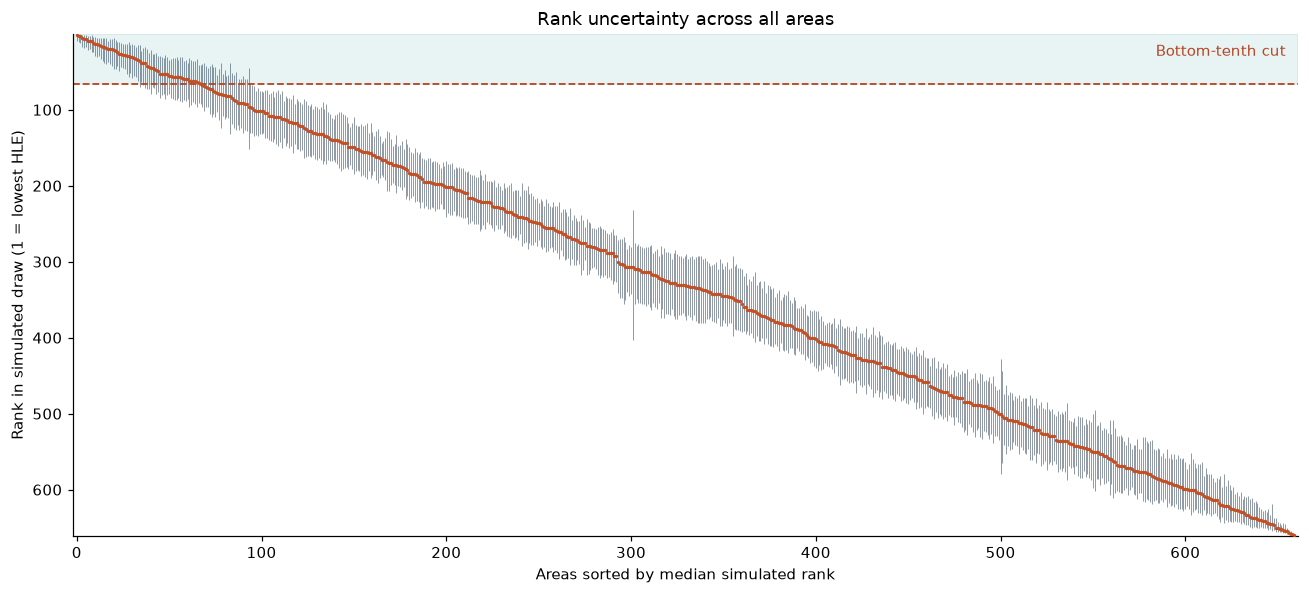

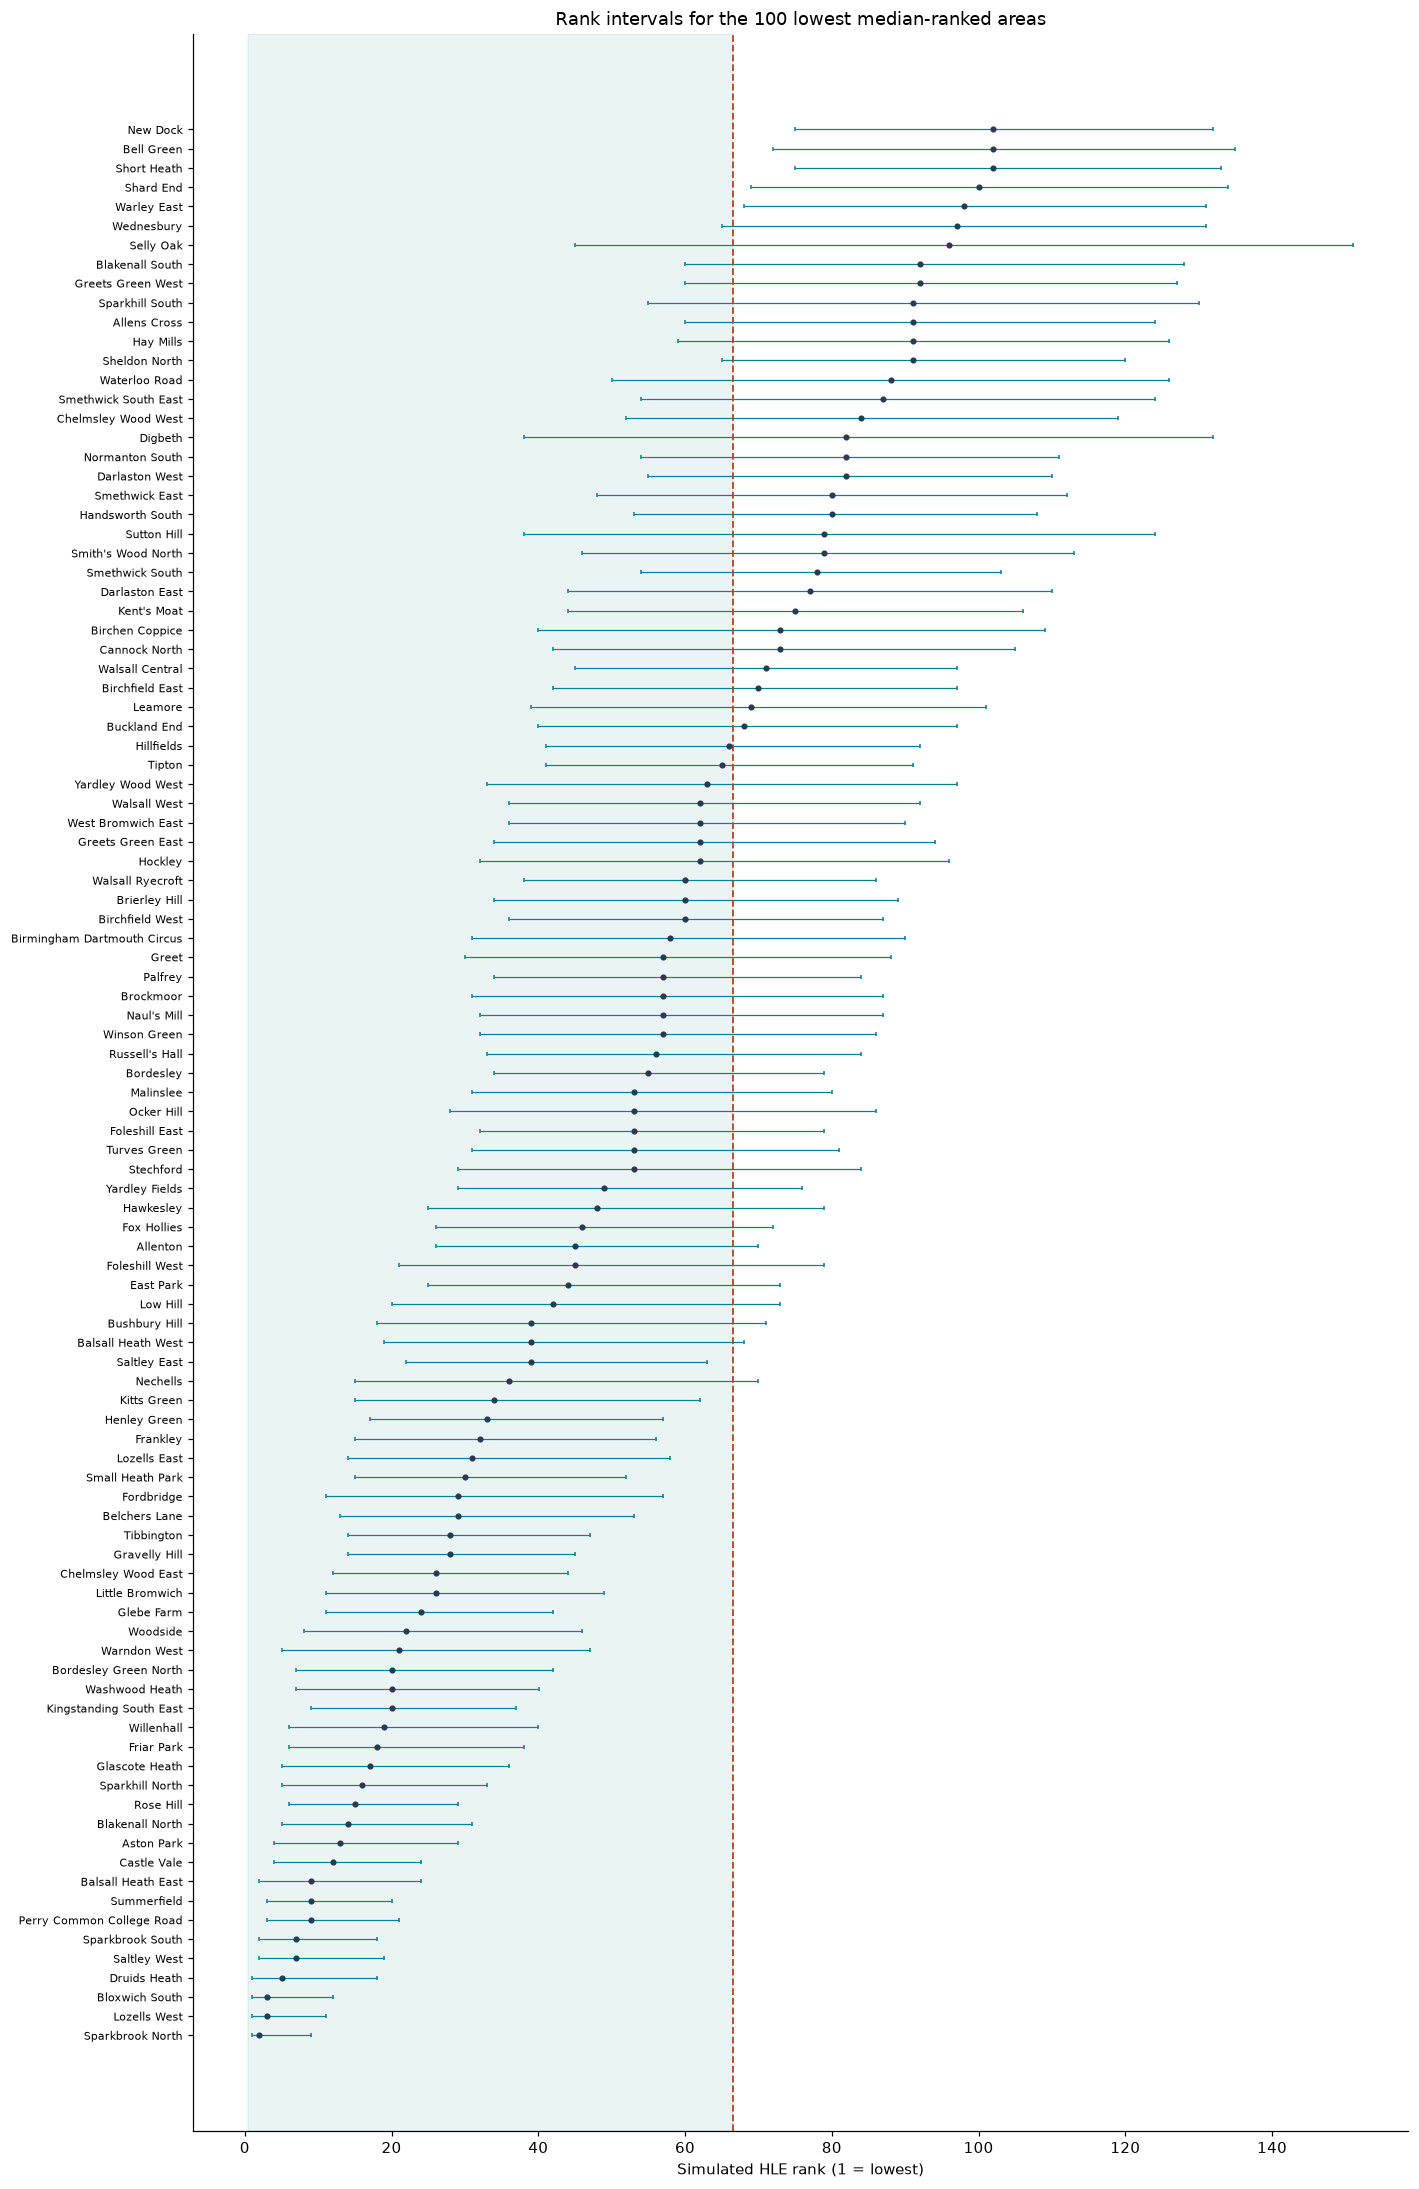

Saved all-area intervals and a named zoom for 100 areas.


In [4]:
save_csv(rank_output, "rank_stability.csv")

ordered = rank_output.sort_values(["median_simulated_rank", "area_code"], kind="mergesort").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(ordered))
ax.axhspan(.5, BOTTOM_CUT + .5, color="#087f8c", alpha=.09)
ax.vlines(x, ordered["rank_5th_percentile"], ordered["rank_95th_percentile"],
          color="#243b53", linewidth=.5, alpha=.65)
ax.scatter(x, ordered["median_simulated_rank"], color="#c25024", s=5, linewidths=0, zorder=3)
ax.axhline(BOTTOM_CUT + .5, color="#b54724", linestyle="--", linewidth=1.2)
ax.set(xlabel="Areas sorted by median simulated rank",
       ylabel="Rank in simulated draw (1 = lowest HLE)", title="Rank uncertainty across all areas")
ax.set_xlim(-2, len(ordered) + 1)
ax.set_ylim(EXPECTED_AREAS + .5, .5)
ax.text(.99, .98, "Bottom-tenth cut", transform=ax.transAxes, ha="right", va="top", color="#b54724")
fig.tight_layout()
save_figure(fig, "rank_intervals_all_areas.png")

lowest = ordered.head(100).sort_values(["median_simulated_rank", "area_code"],
                                       ascending=[False, False], kind="mergesort").reset_index(drop=True)
y = np.arange(len(lowest))
lower = lowest["median_simulated_rank"] - lowest["rank_5th_percentile"]
upper = lowest["rank_95th_percentile"] - lowest["median_simulated_rank"]
fig, ax = plt.subplots(figsize=(13, 20))
ax.axvspan(.5, BOTTOM_CUT + .5, color="#087f8c", alpha=.08)
ax.errorbar(lowest["median_simulated_rank"], y, xerr=np.vstack([lower, upper]),
            fmt="o", color="#243b53", ecolor="#087f8c", markersize=3, capsize=1.5, linewidth=.8)
ax.axvline(BOTTOM_CUT + .5, color="#b54724", linestyle="--", linewidth=1.2)
ax.set_yticks(y, lowest["local_area_name"], fontsize=7)
ax.set(xlabel="Simulated HLE rank (1 = lowest)", title="Rank intervals for the 100 lowest median-ranked areas")
ax.invert_yaxis()
fig.tight_layout()
save_figure(fig, "rank_intervals_lowest_100.png")
print(f"Saved all-area intervals and a named zoom for {len(lowest)} areas.")

## Mapping the chance of being in the bottom tenth

I use the same boundary source, code-field check and projected boundaries as Notebook 04. Colour shows the simulated probability of an area ranking in the bottom tenth; it is not a map of certain outcomes.

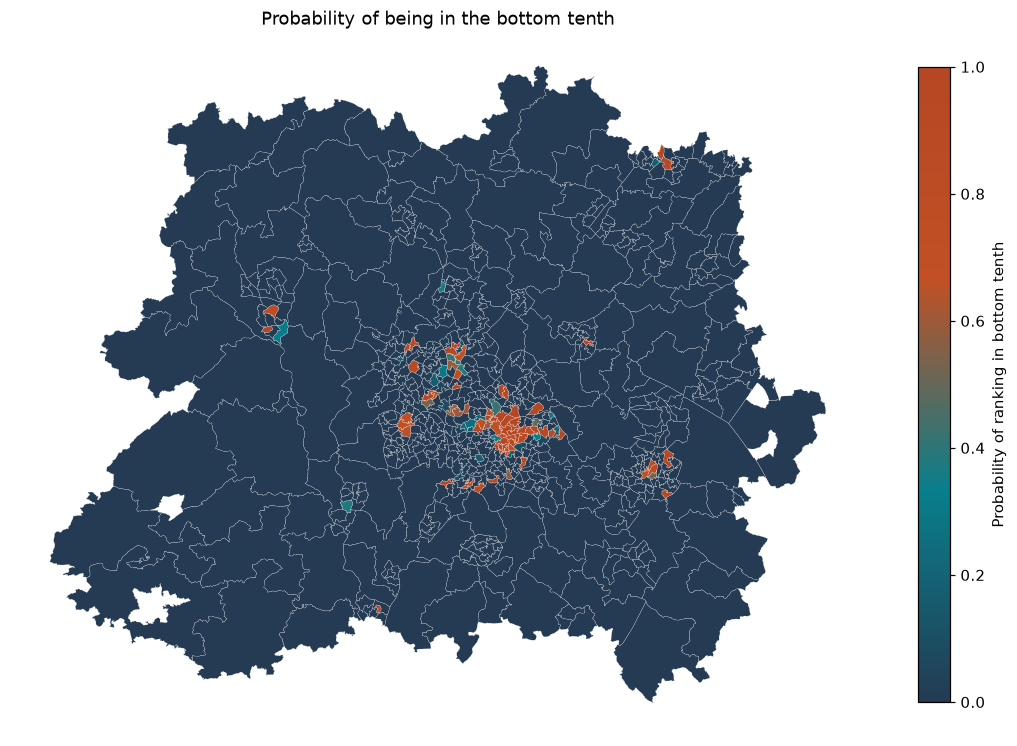

Mapped bottom-tenth probabilities for 660 MSOA areas using Notebook 04 boundaries.


In [5]:
boundary_path = raw_file("ons_msoa21_boundaries_exploratory_west_midlands.geojson")
boundaries = gpd.read_file(boundary_path)
boundary_code_field = next(field for field in boundaries.columns if field != "geometry"
    and boundaries[field].astype(str).str.fullmatch(r"[EW]020\d{5}").all())
assert boundaries[boundary_code_field].is_unique and len(boundaries) == EXPECTED_AREAS
assert set(boundaries[boundary_code_field]) == set(rank_output["area_code"])
assert boundaries.crs is not None and boundaries.geometry.notna().all()
assert boundaries.geometry.is_valid.all()
boundaries_by_code = boundaries.set_index(boundary_code_field).to_crs(27700)
assert boundaries_by_code.crs.to_epsg() == 27700 and "MSOA21NM" in boundaries_by_code.columns
map_data = boundaries_by_code.join(
    rank_output.set_index("area_code")[["p_bottom_10_percent"]],
    how="left", validate="one_to_one")
assert map_data["p_bottom_10_percent"].notna().all()
cmap = LinearSegmentedColormap.from_list(
    "unit_2_palette", ["#243b53", "#087f8c", "#c25024", "#b54724"])
fig, ax = plt.subplots(figsize=(10, 8))
map_data.plot(column="p_bottom_10_percent", cmap=cmap, vmin=0, vmax=1,
              linewidth=.12, edgecolor="#ffffff", ax=ax)
scalar = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
scalar.set_array([])
fig.colorbar(scalar, ax=ax, shrink=.75, label="Probability of ranking in bottom tenth")
ax.set_title("Probability of being in the bottom tenth")
ax.set_axis_off()
fig.tight_layout()
save_figure(fig, "probability_bottom_tenth_map.png")
print(f"Mapped bottom-tenth probabilities for {len(map_data)} MSOA areas using Notebook 04 boundaries.")

## Saving the outputs

I save one row per area, the figures, a data dictionary, and a JSON summary. The summary records the interval derivation, independence assumption, confidence-band rules and headline counts.

In [6]:
rank_dictionary = {
    "area_code": ("MSOA21 identifier", "Unique area code used by the joined table"),
    "local_area_name": ("text", "Familiar name of the MSOA area"),
    "published_hle": ("years", "Published average healthy life expectancy estimate"),
    "published_rank": ("rank", "Rank of published estimate; 1 is lowest and ties follow area-code order"),
    "median_simulated_rank": ("rank", "Median rank across simulated HLE draws"),
    "rank_5th_percentile": ("rank", "5th percentile of simulated ranks"),
    "rank_95th_percentile": ("rank", "95th percentile of simulated ranks"),
    "rank_interval_width_places": ("places", "95th percentile rank minus 5th percentile rank"),
    "p_bottom_10_percent": ("probability 0–1", "Share of draws with rank at or below the bottom-tenth cut"),
    "bottom_10_confidence": ("category", "Band for bottom-tenth probability using the stated thresholds"),
    "p_top_10_percent": ("probability 0–1", "Share of draws with rank at or above the top-tenth first rank"),
    "top_10_confidence": ("category", "Band for top-tenth probability using the stated thresholds"),
    "hle_male_imputed": ("boolean", "Male HLE imputation flag; retained, not dropped"),
    "student_dominated": ("boolean", "Student-area flag; retained, not dropped"),
    "visitor_hub": ("boolean", "Visitor-hub flag; retained, not dropped"),
}
dictionary_rows = [
    {"file":"rank_stability.csv","column":c,"meaning":rank_dictionary[c][1],
     "unit":rank_dictionary[c][0],"missing_rule":"No missing values"}
    for c in rank_output.columns
]

def flatten_json(value, prefix=""):
    if isinstance(value, dict):
        for key, child in value.items():
            yield from flatten_json(child, f"{prefix}.{key}" if prefix else str(key))
    elif isinstance(value, list):
        if value:
            for child in value:
                yield from flatten_json(child, f"{prefix}[]")
        else:
            yield prefix, []
    else:
        yield prefix, value

summary_meanings = {
    "area_count":("areas","Areas included in the ranking simulation"),
    "simulations":("draws","Independent HLE draws used for the ranking simulation"),
    "batch_size":("draws","Simulations generated in each batch"),
    "seed":("seed","Fixed NumPy random generator seed"),
    "bottom_tenth_cutoff_rank":("rank","Highest rank included in the bottom tenth"),
    "top_tenth_first_rank":("rank","Lowest rank included in the top tenth"),
    "published_lowest_area_count":("areas","Areas among the lowest published estimates"),
    "published_lowest_confidently_in_bottom_tenth":("areas","Published-lowest areas with bottom probability at least 0.95"),
    "median_rank_interval_width_overall_places":("places","Median 90% rank-interval width across all areas"),
    "median_rank_interval_width_middle_third_places":("places","Median 90% rank-interval width in published middle third"),
    "areas_with_rank_interval_width_over_100_places":("areas","Areas whose rank interval is wider than 100 places"),
    "output_folder":("project-relative path","Folder containing this notebook's outputs"),
}
for key, value in flatten_json(summary):
    if key in summary_meanings:
        unit, meaning = summary_meanings[key]
    elif key.startswith(("bottom_tenth_confidence_counts.", "top_tenth_confidence_counts.")):
        unit, meaning = "areas", f"Count in confidence band {key.split('.')[-1]}"
    else:
        unit, meaning = "text or rule", "Recorded method, assumption, threshold or definition"
    dictionary_rows.append({"file":"results_summary.json","column":key,"meaning":meaning,
                            "unit":unit,"missing_rule":"No missing values"})
for c, (unit, meaning) in {
    "file":("text","Filename described by this row"),
    "column":("text","CSV column or dotted JSON path; [] marks repeated items"),
    "meaning":("text","What the field records"),
    "unit":("text","Measurement unit or value type"),
    "missing_rule":("text","Meaning of a blank value"),
}.items():
    dictionary_rows.append({"file":"data_dictionary.csv","column":c,"meaning":meaning,
                            "unit":unit,"missing_rule":"No missing values"})
data_dictionary = pd.DataFrame(dictionary_rows)
assert not data_dictionary.duplicated(["file","column"]).any()
assert set(data_dictionary.query("file == 'rank_stability.csv'")["column"]) == set(rank_output.columns)
assert set(data_dictionary.query("file == 'results_summary.json'")["column"]) == {k for k,_ in flatten_json(summary)}
save_json(summary, "results_summary.json")
save_csv(data_dictionary, "data_dictionary.csv")
print(f"Saved {len(rank_output)} area rows, {len(list(figure_folder.glob('*.png')))} figures and a complete data dictionary.")

Saved 660 area rows, 3 figures and a complete data dictionary.


In [7]:
print("Ethics questions addressed: Q4, Q14 and Q20.")
print(f"Median interval width overall: {median_width_all:.2f}; middle third: {median_width_middle:.2f}.")
print(f"Published-lowest areas confidently in the bottom tenth: {published_low_confident} of {BOTTOM_CUT}.")
print(f"Areas with intervals wider than 100 places: {over_100}.")

Ethics questions addressed: Q4, Q14 and Q20.
Median interval width overall: 65.00; middle third: 69.52.
Published-lowest areas confidently in the bottom tenth: 35 of 66.
Areas with intervals wider than 100 places: 8.


## What this means ethically

For Q14, the intervals show whether a single rank would make the evidence look more certain than it is. The bottom-tenth probabilities distinguish areas whose estimates repeatedly fall in that group from areas whose rank moves across its boundary.

For Q4 and Q20, the risk is an inaccurate description of a place. I keep the ranking question, name the areas, retain the imputation and context flags, and show uncertainty alongside the estimate. This simulation does not turn area-level associations into statements about residents or causes.